# Классификация ценового сегмента жилой недвижимости

**Проект:** House Prices AI, исторические сделки с жилой недвижимостью в городе Эймс (США).

**Цель исследования:** сопоставить классификаторы, определяющие принадлежность объекта к сегменту стоимости от $200 000. Целевая переменная принимает значение `1` для дорогого сегмента и `0` для остальных объектов.

Для оценки использованы DummyClassifier, LogisticRegression, RandomForestClassifier, XGBoostClassifier и MLPClassifier. При сравнении рассматриваются Accuracy, Balanced Accuracy, Precision, Recall, F1 и ROC-AUC. Значимость признаков и объяснение отдельных прогнозов изучаются на следующем этапе исследования.

## 1. Методика оценки

Для сохранения доли положительного класса применяется `StratifiedKFold` с пятью разбиениями. В каждом разбиении предобработка исходных характеристик обучается только на соответствующей тренировочной части, что предотвращает утечку информации из валидационных объектов при заполнении пропусков, IQR-обработке, стандартизации и категориальном кодировании.

OOF-прогнозы формируются по одному разу для каждого объекта. Они используются для построения кривых ROC и Precision–Recall и матриц ошибок. При этом метрики, рассчитанные на объединённых OOF-прогнозах, могут немного отличаться от среднего по пяти фолдам. Внешняя тестовая выборка на данном этапе не используется.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import Image, display
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, average_precision_score

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "outputs" / "classification"

required = ["cv_summary.csv", "cv_folds.csv", "oof_models.csv", "mlp_learning_history.csv"]
missing = [name for name in required if not (RESULTS / name).exists()]
if missing:
    raise FileNotFoundError(f"Не найдены результаты {missing}. Запустите python -m house_prices_ai.classification из корня проекта")
summary = pd.read_csv(RESULTS / "cv_summary.csv")
folds = pd.read_csv(RESULTS / "cv_folds.csv")
oof = pd.read_csv(RESULTS / "oof_models.csv")
mlp_history = pd.read_csv(RESULTS / "mlp_learning_history.csv")
mlp_details = json.loads((RESULTS / "mlp_training_summary.json").read_text(encoding="utf-8"))
display(summary[["Model","Accuracy_mean","Precision_mean","Recall_mean","F1_mean","ROC_AUC_mean"]].round(4))

,Model,Accuracy_mean,Precision_mean,Recall_mean,F1_mean,ROC_AUC_mean
0,XGBoostClassifier,0.9401,0.9071,0.8910,0.8977,0.9825
1,MLPClassifier,0.9350,0.9034,0.8766,0.8892,0.9792
2,LogisticRegression,0.9289,0.8861,0.8765,0.8808,0.9746
3,RandomForestClassifier,0.9238,0.9114,0.8251,0.8646,0.9802
4,DummyClassifier,0.7021,0.0000,0.0000,0.0000,0.5000


## 2. Состав ценовых сегментов

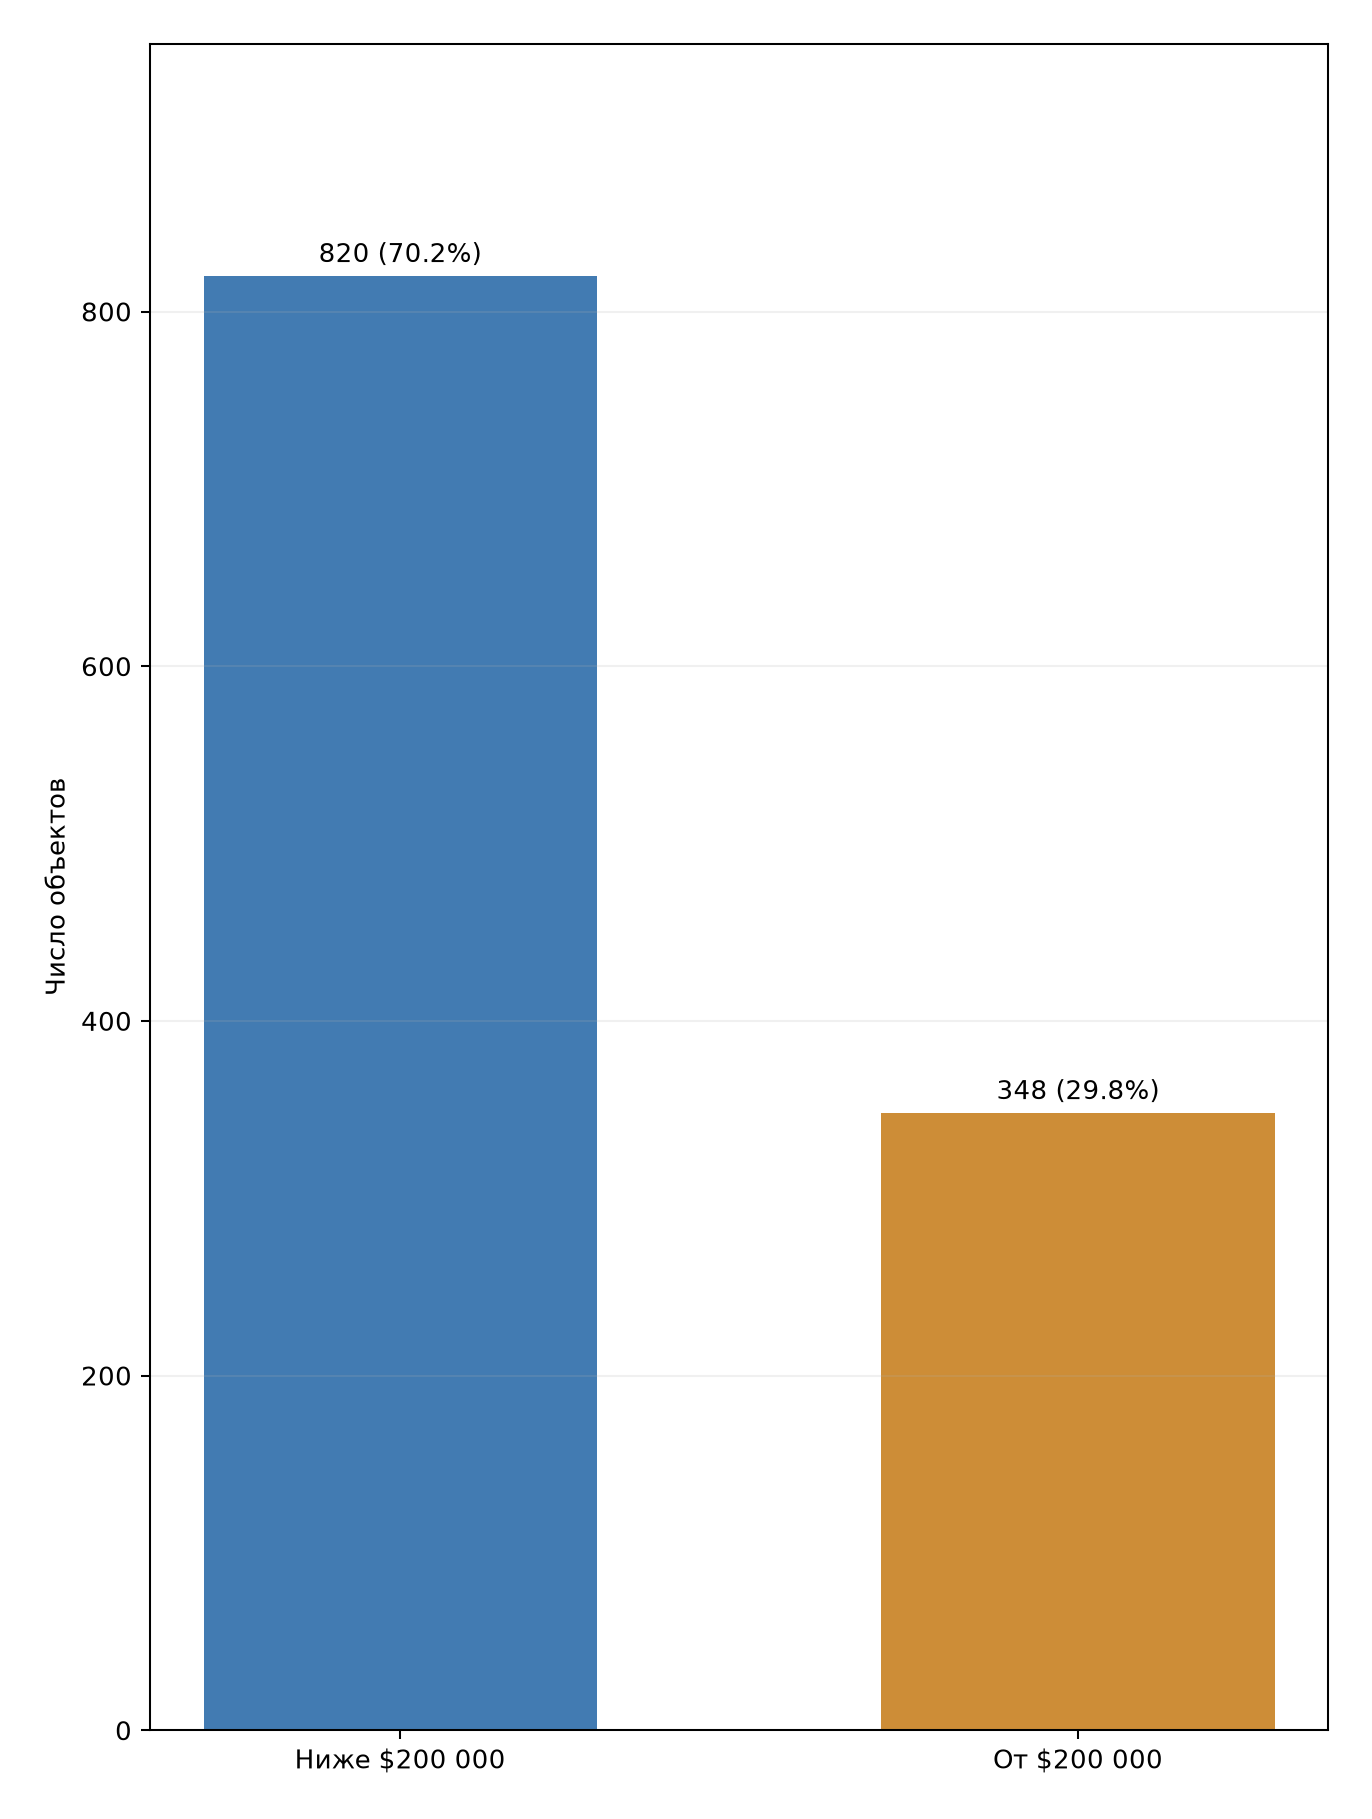

In [2]:
display(Image(filename=str(RESULTS / "figures" / "4_1_class_distribution.png")))

*Рисунок 4.1 — Распределение наблюдений по ценовым сегментам.*

Положительный класс составляет около 30% обучающих наблюдений, поэтому общая доля правильных решений не может служить единственным критерием качества. Для выявления дорогих объектов необходимо отдельно учитывать Precision и Recall. Пятикратная стратификация сохраняет приблизительно одинаковую представленность классов в разных разбиениях.

## 3. Сравнение качества классификаторов

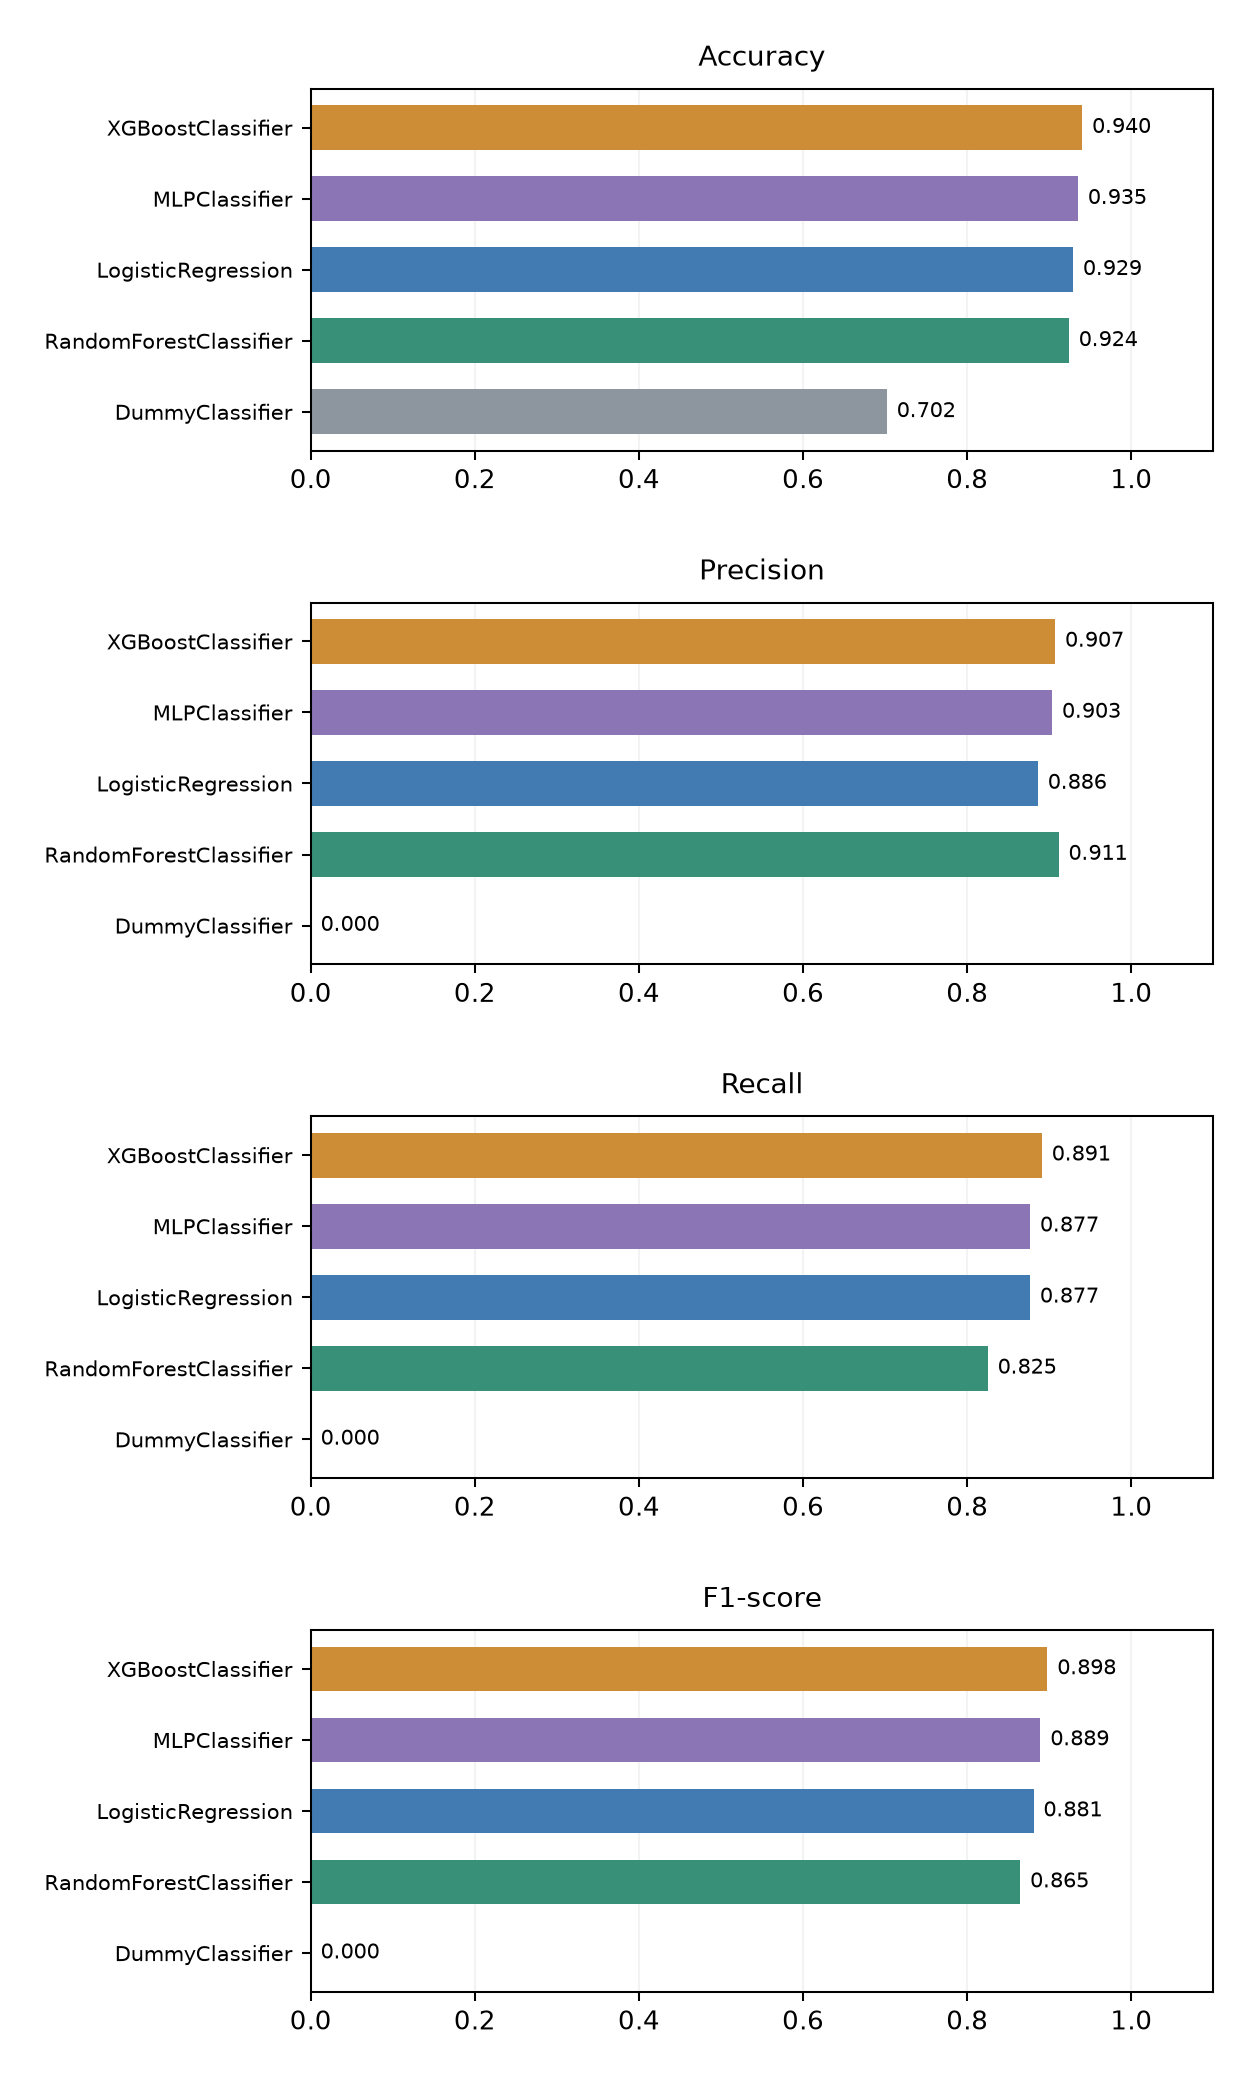

In [3]:
display(Image(filename=str(RESULTS / "figures" / "4_2_comparison_metrics.png")))

*Рисунок 4.2 — Сравнение Accuracy, Precision, Recall и F1-score по пяти разбиениям.*

На диаграмме видно, насколько близки некоторые обучаемые модели по средней точности классификации и ранжирования вероятностей. DummyClassifier показывает формально приемлемую Accuracy за счёт преобладающего класса, но имеет нулевой F1, поскольку не находит дорогие дома. Показатель ROC-AUC отдельно характеризует способность упорядочивать объекты по вероятности положительного класса, поэтому рейтинг по нему может отличаться от рейтинга по F1.

Сравнение проводилось при исходных настройках алгоритмов и стандартном пороге принятия решения. Малые различия средних метрик сами по себе не доказывают статистически значимого превосходства.

In [4]:
display(summary[["Model", "Accuracy_mean", "BalancedAccuracy_mean", "Precision_mean", "Recall_mean", "F1_mean", "ROC_AUC_mean"]].round(4))
display(folds.pivot(index="Fold", columns="Model", values="F1").round(4))
best = summary.iloc[0]
print(f"Наибольший средний F1: {best['Model']} = {best['F1_mean']:.4f}")

,Model,Accuracy_mean,BalancedAccuracy_mean,Precision_mean,Recall_mean,F1_mean,ROC_AUC_mean
0,XGBoostClassifier,0.9401,0.9260,0.9071,0.8910,0.8977,0.9825
1,MLPClassifier,0.9350,0.9182,0.9034,0.8766,0.8892,0.9792
2,LogisticRegression,0.9289,0.9139,0.8861,0.8765,0.8808,0.9746
3,RandomForestClassifier,0.9238,0.8955,0.9114,0.8251,0.8646,0.9802
4,DummyClassifier,0.7021,0.5000,0.0000,0.0000,0.0000,0.5000


Model,DummyClassifier,LogisticRegression,MLPClassifier,RandomForestClassifier,XGBoostClassifier
Fold,,,,,
1,0.0,0.8794,0.8571,0.8333,0.8811
2,0.0,0.8971,0.9078,0.8824,0.9296
3,0.0,0.8489,0.8613,0.8065,0.8372
4,0.0,0.9254,0.9403,0.8971,0.9420
5,0.0,0.8531,0.8794,0.9037,0.8986


Наибольший средний F1: XGBoostClassifier = 0.8977


## 4. Анализ ошибок классификации

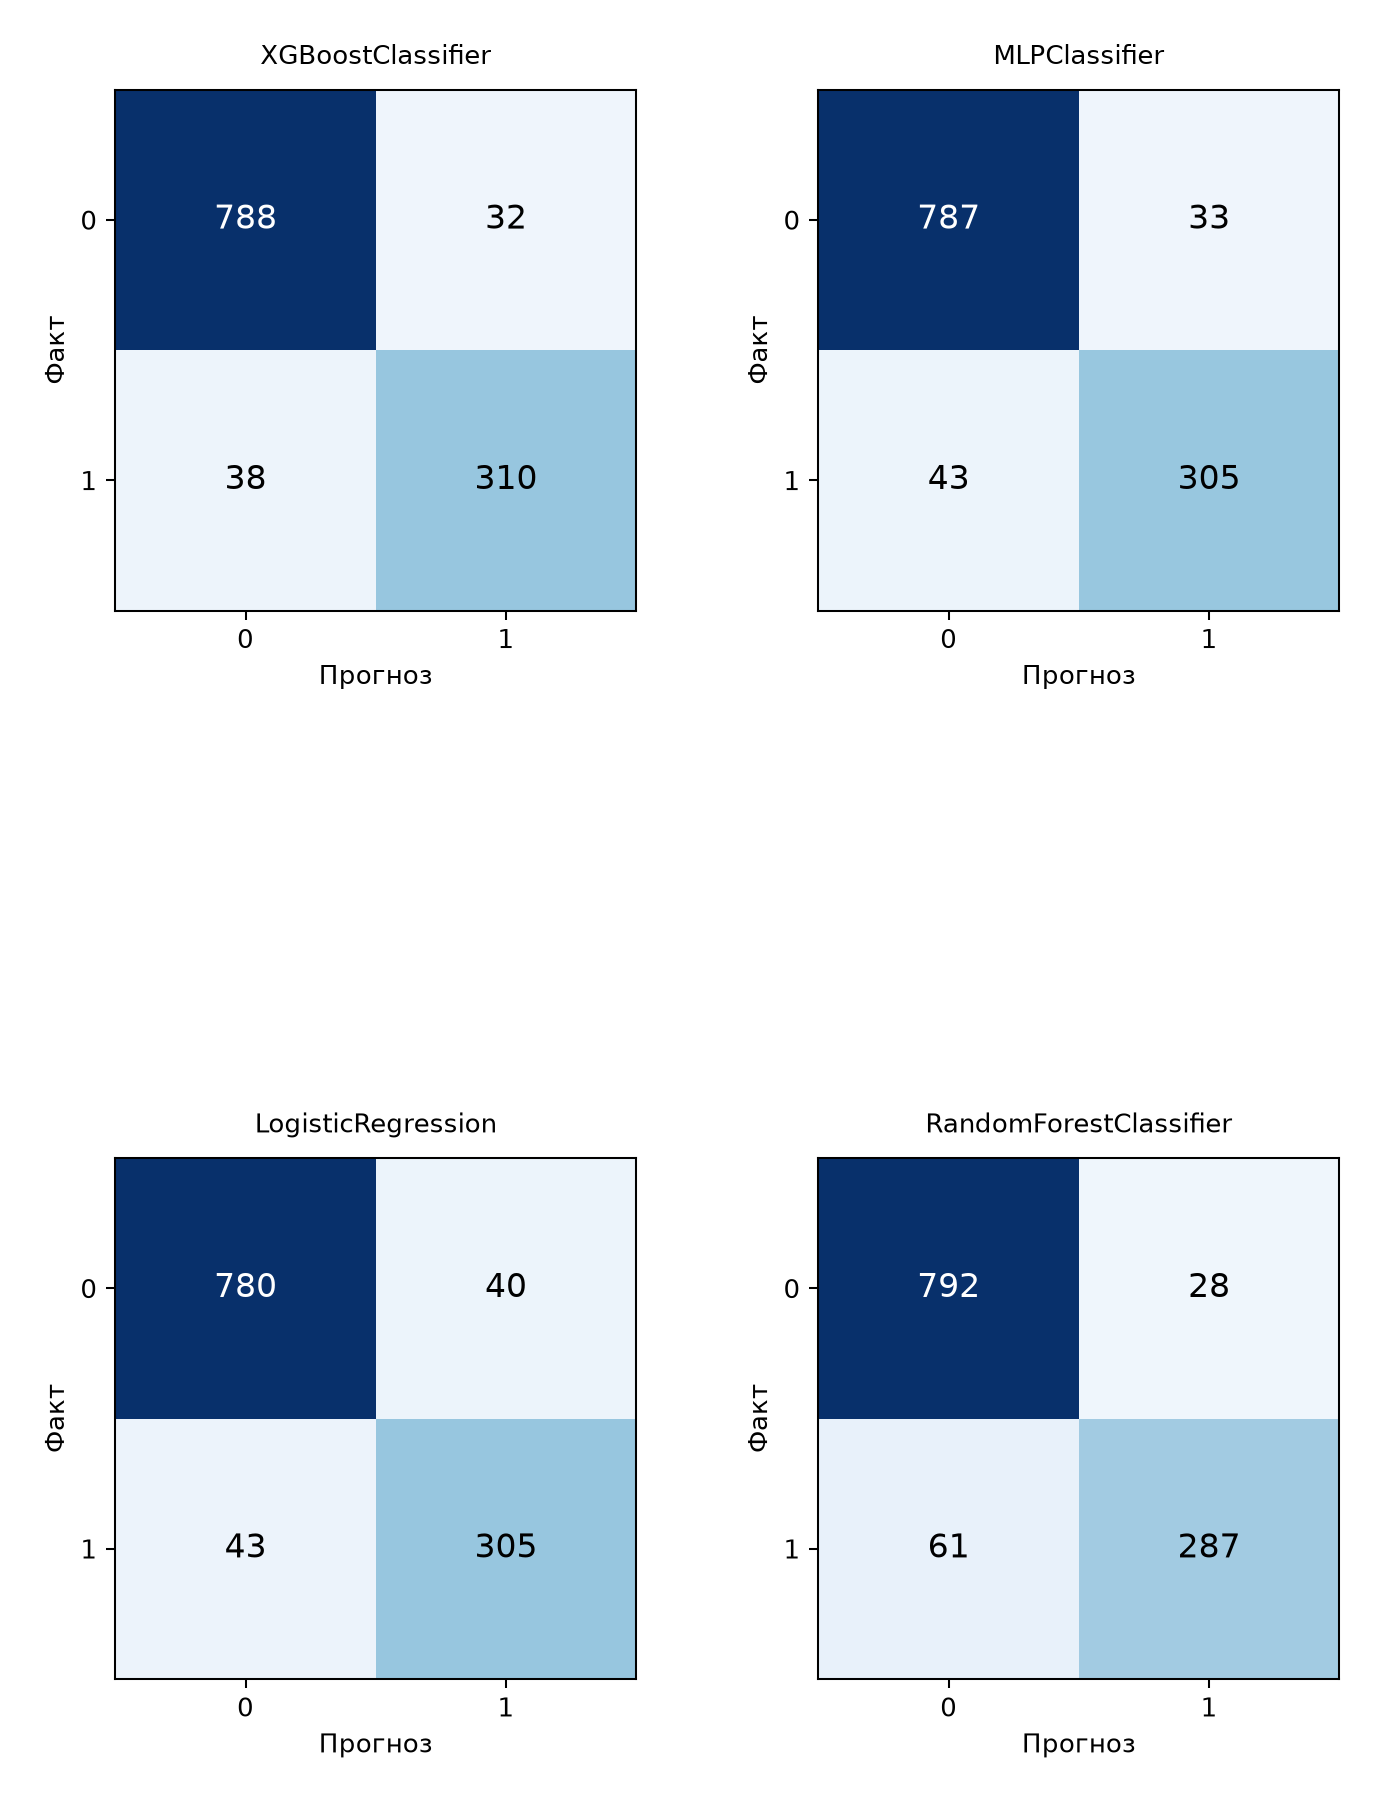

In [5]:
display(Image(filename=str(RESULTS / "figures" / "4_3_confusion_matrices.png")))

*Рисунок 4.3 — Матрицы ошибок четырёх обучаемых классификаторов на объединённых OOF-прогнозах.*

По горизонтали указан предсказанный класс, по вертикали — фактический. Ошибка FP соответствует отнесению недорогого дома к дорогому сегменту, ошибка FN означает пропуск действительно дорогого объекта. Сопоставление матриц показывает, что модель с максимальным Precision может пропускать больше объектов положительного класса. Поэтому при выборе классификатора следует учитывать баланс разных типов ошибок.

In [6]:
rows=[]
for name in summary["Model"]:
    if name == "DummyClassifier":
        continue
    true = oof["ActualClass"].to_numpy()
    pred = oof[f"PredictedClass__{name}"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(true, pred, labels=[0, 1]).ravel()
    rows.append({"Модель":name, "TN":tn, "FP":fp, "FN":fn, "TP":tp,
                 "OOF F1":f1_score(true,pred)})
display(pd.DataFrame(rows).round(4))

,Модель,TN,FP,FN,TP,OOF F1
0,XGBoostClassifier,788,32,38,310,0.8986
1,MLPClassifier,787,33,43,305,0.8892
2,LogisticRegression,780,40,43,305,0.8802
3,RandomForestClassifier,792,28,61,287,0.8658


## 5. Сравнение ранжирования объектов

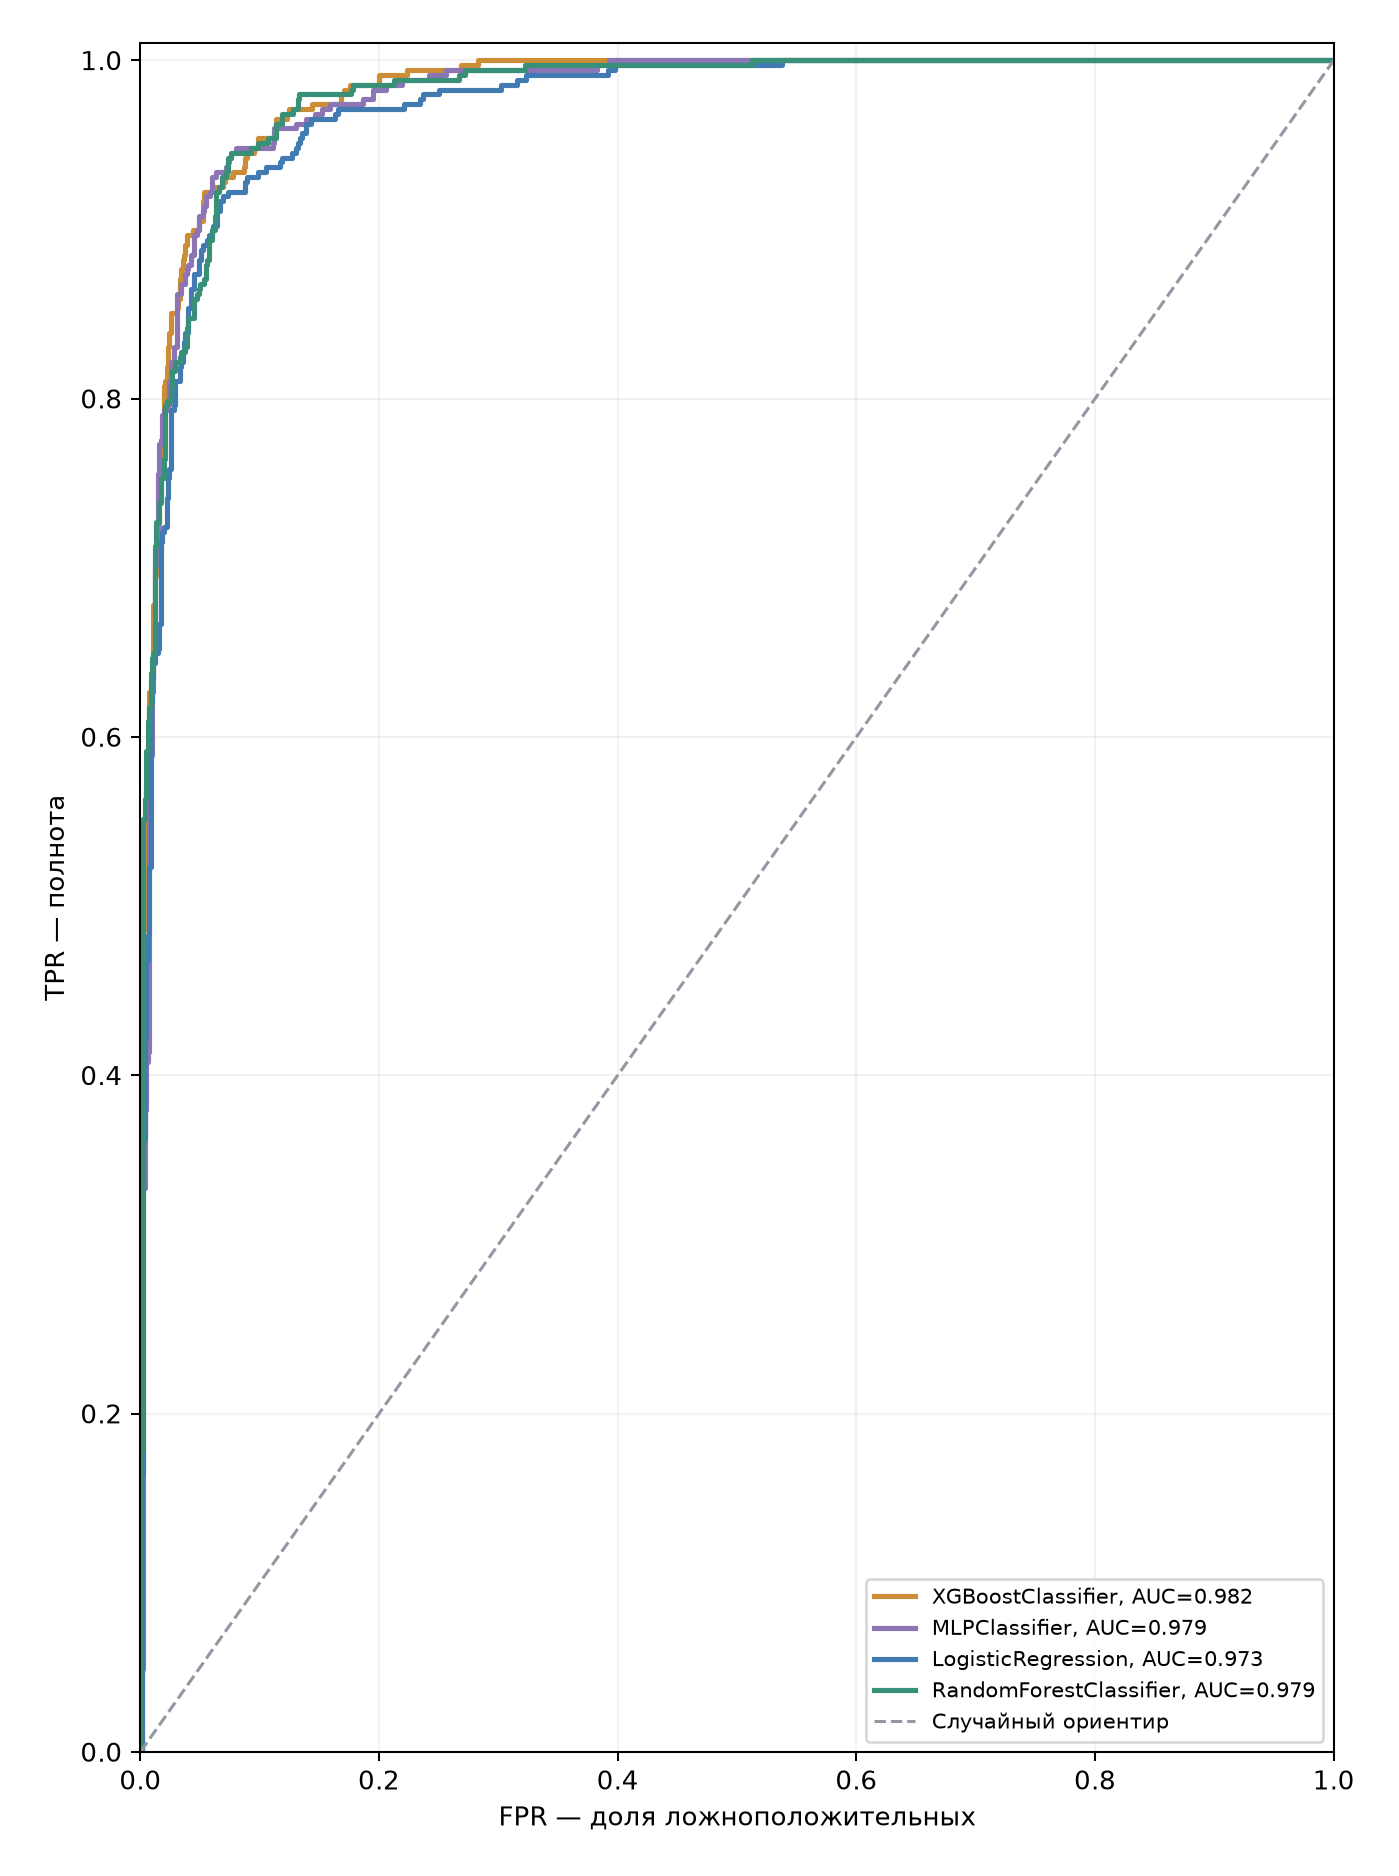

In [7]:
display(Image(filename=str(RESULTS / "figures" / "4_4_roc_comparison.png")))

*Рисунок 4.4 — ROC-кривые обучаемых классификаторов по объединённым OOF-вероятностям.*

ROC-кривая показывает соотношение доли верно найденных положительных объектов и ложноположительных решений при изменении порога. Чем ближе кривая к левому верхнему углу, тем лучше разделение классов. Значения AUC в легенде рассчитаны по всем OOF-прогнозам, а не как среднее AUC по разбиениям.

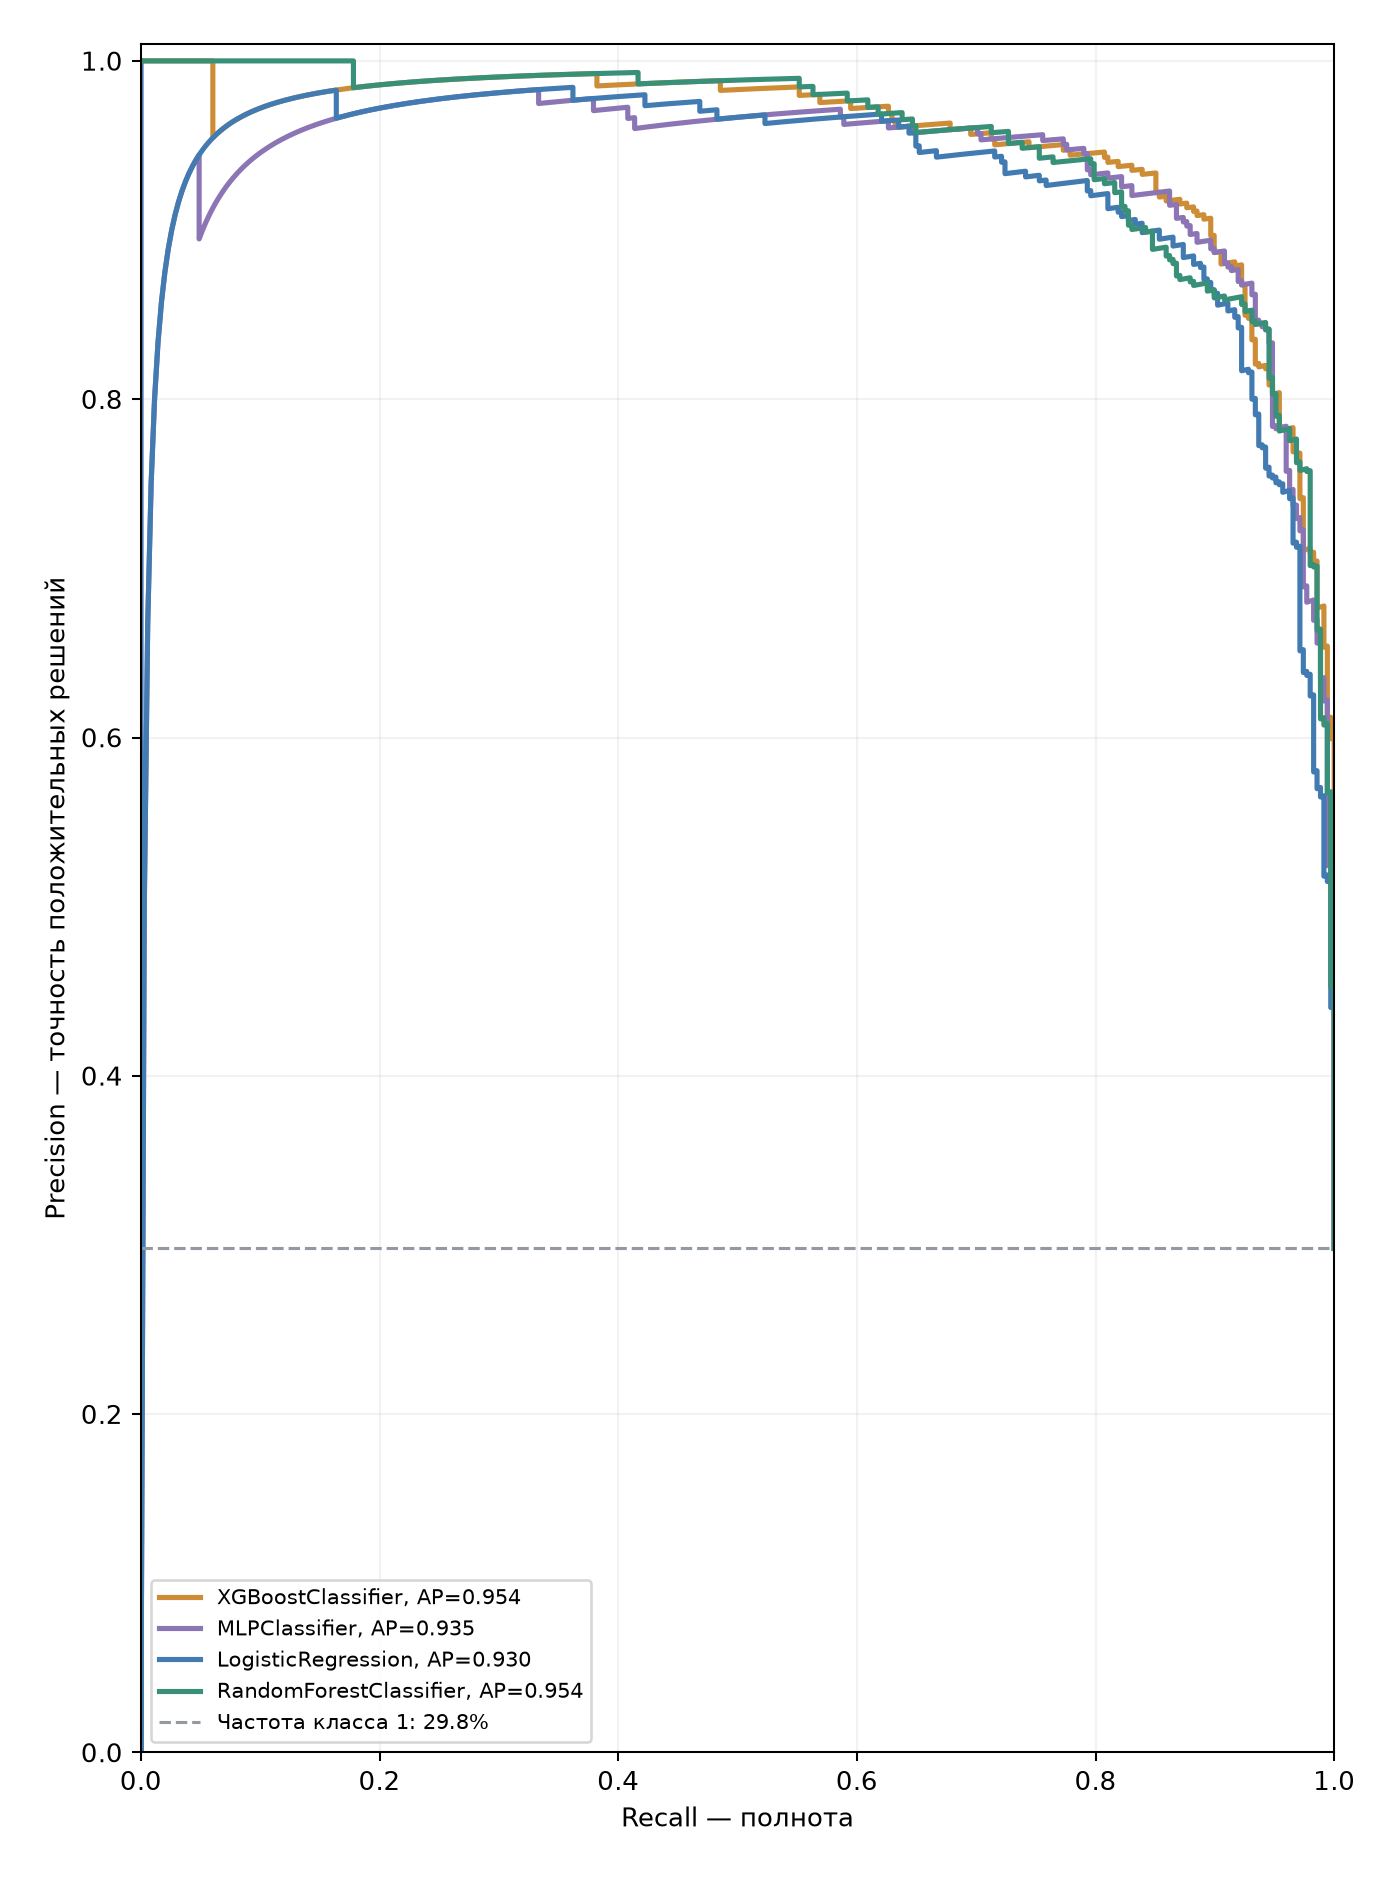

In [8]:
display(Image(filename=str(RESULTS / "figures" / "4_5_precision_recall.png")))

*Рисунок 4.5 — Кривые Precision–Recall по объединённым OOF-вероятностям.*

При увеличении полноты обнаружения дорогих домов обычно приходится допускать больше ложноположительных решений. Поэтому Precision–Recall-кривые позволяют оценить компромисс между пропусками и ложными срабатываниями. Горизонтальная линия соответствует доле положительного класса. В легенде представлена Average Precision (AP), которая не тождественна площади ROC-кривой.

Совместный анализ матриц ошибок, ROC и Precision–Recall показывает, что качество разделения классов следует оценивать как по выбранному порогу, так и при варьировании порога.

## 6. Динамика обучения нейросетевого классификатора

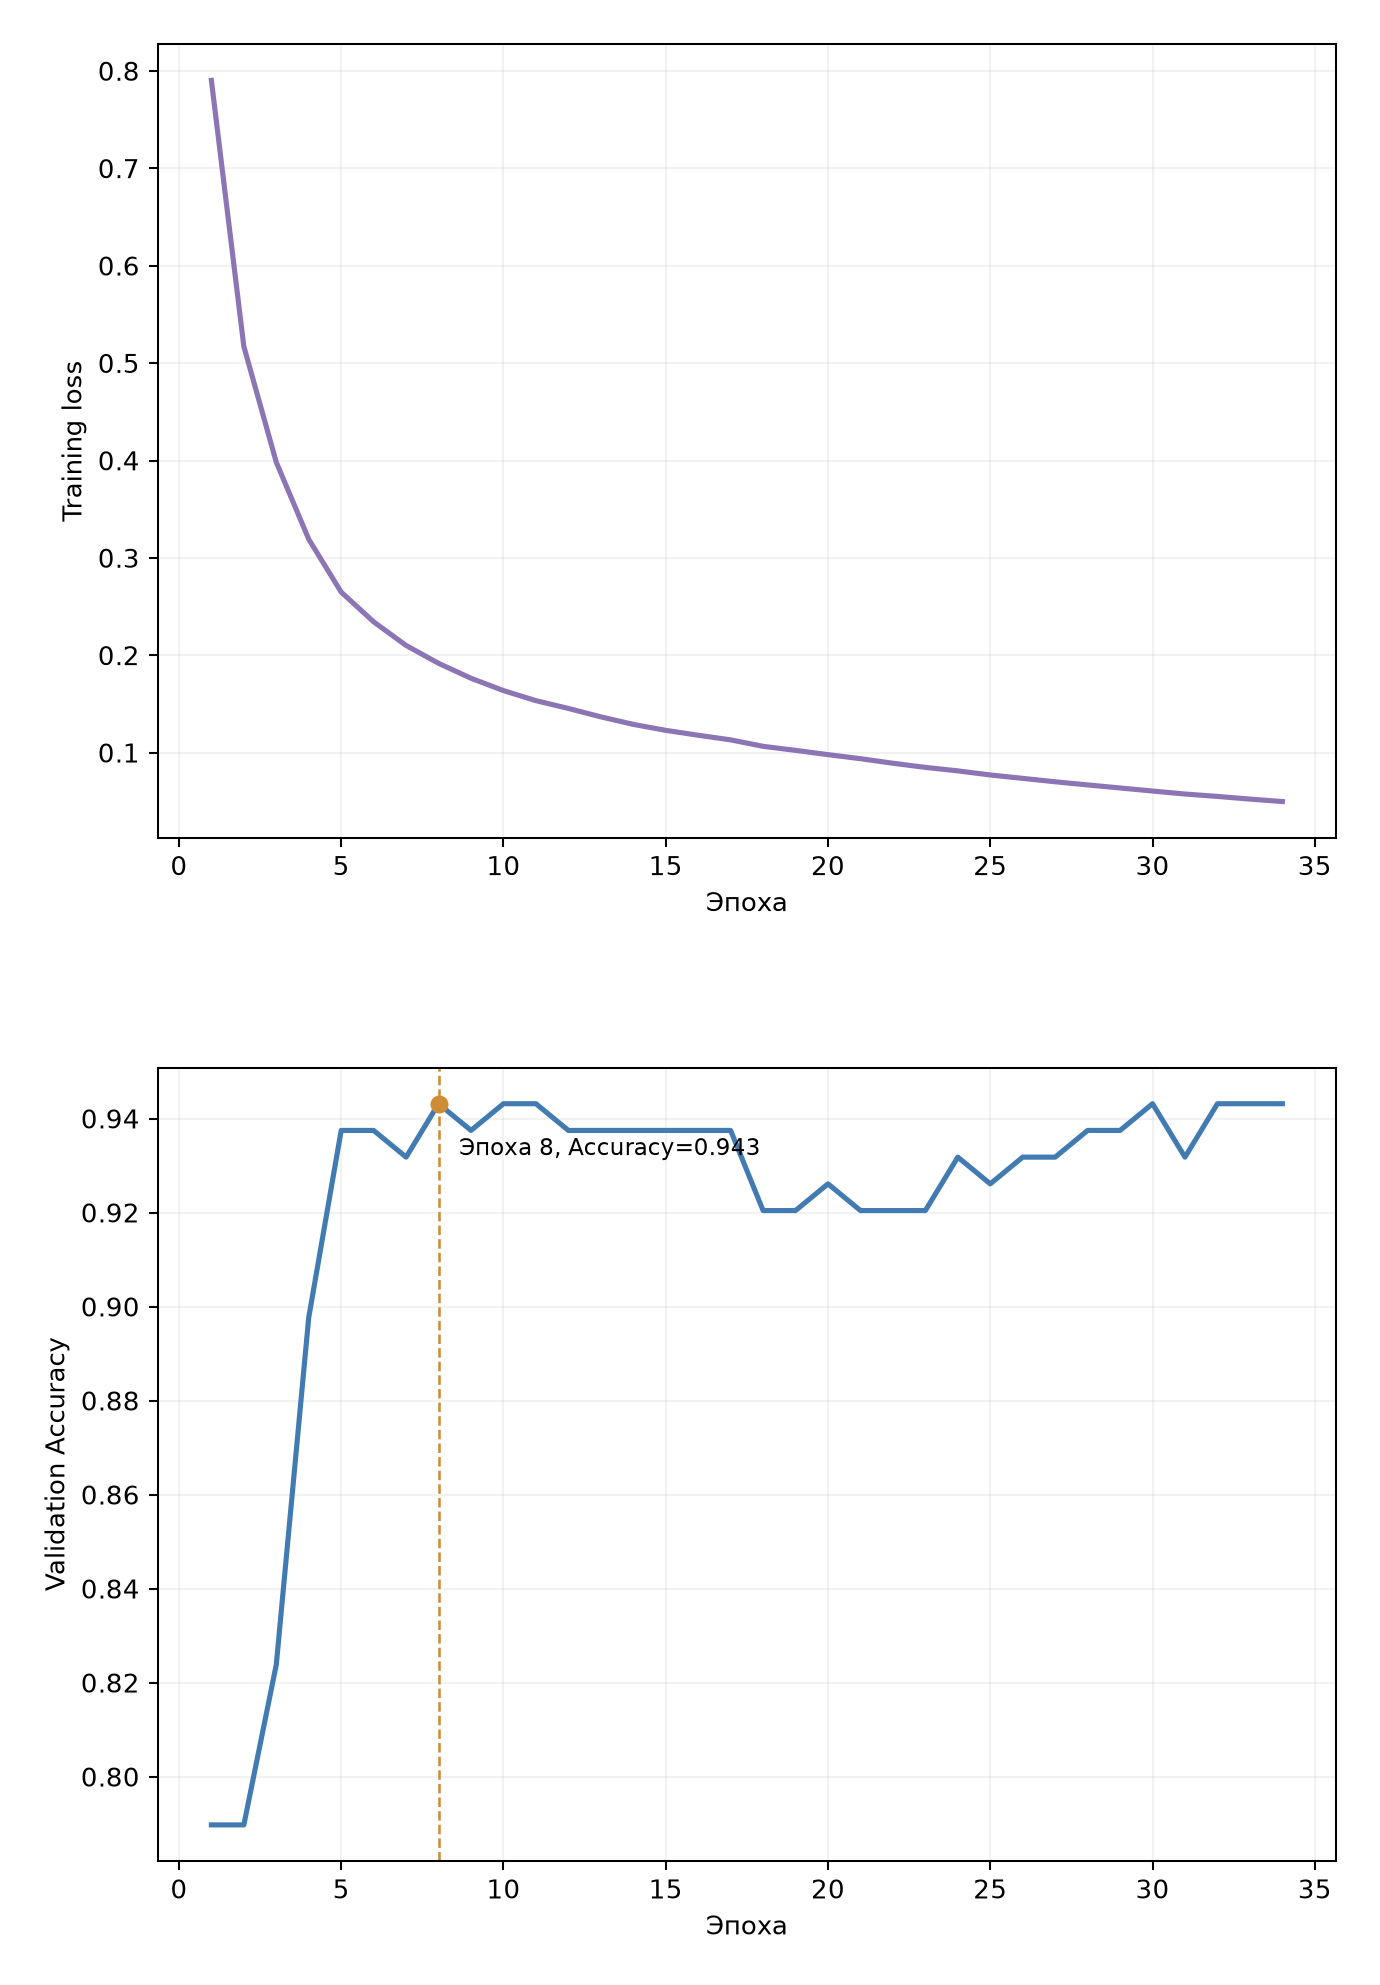

In [9]:
display(Image(filename=str(RESULTS / "figures" / "4_6_mlp_training.png")))

*Рисунок 4.6 — Динамика Training Loss и внутренней Validation Accuracy многослойного персептрона.*

Нейросеть обучается методом обратного распространения ошибки с оптимизатором Adam. По мере обучения функция потерь на тренировочной части обычно уменьшается, но качество на внутренней валидации может достичь максимума раньше окончания обучения. Механизм Early Stopping ориентируется здесь на **Validation Accuracy**, а не на F1 или ROC-AUC. Значения на рисунке получены при отдельном обучении на полном внешнем train и не являются историей пятифолдовой кросс-валидации. Поскольку внутренняя валидация MLP создаётся после подгонки общей предобработки, её Accuracy служит критерием остановки, а не независимой оценкой качества на новых данных.

In [10]:
print(f"Всего эпох: {mlp_details['epochs']}")
print(f"Лучшая эпоха: {mlp_details['best_epoch']}")
print(f"Лучшая внутренняя Validation Accuracy: {mlp_details['best_validation_accuracy']:.4f}")
print(f"Loss в начале и конце обучения: {mlp_details['first_training_loss']:.5f} → {mlp_details['last_training_loss']:.5f}")

Всего эпох: 34
Лучшая эпоха: 8
Лучшая внутренняя Validation Accuracy: 0.9432
Loss в начале и конце обучения: 0.79037 → 0.04991


## 7. Подбор гиперпараметров XGBoost

Для экспериментального подбора применяется `RandomizedSearchCV`. Критерий выбора — средний F1 в трёхфолдовой стратифицированной кросс-валидации, предобработка входит в каждый обучаемый Pipeline. Исследуются число деревьев, глубина, скорость обучения, доля используемых наблюдений и признаков, минимальный вес узла и коэффициент L2-регуляризации.

Увеличение числа деревьев при меньшем `learning_rate` позволяет делать более мелкие последовательные корректировки. Ограничение `max_depth` сдерживает сложность отдельных деревьев, `subsample` и `colsample_bytree` вносят стохастичность, а `min_child_weight` и `reg_lambda` регулируют сложность и величины обновлений. Найденные параметры являются лучшими **среди опробованных комбинаций**, но не гарантированно оптимальными. Диапазоны поиска ограничены исходной конфигурацией модели и разумной сложностью деревьев для небольшого набора данных.

| Гиперпараметр | Исследуемые значения |
|---|---|
| `n_estimators` | 200, 300, 450 |
| `max_depth` | 2, 3, 4 |
| `learning_rate` | 0.025, 0.05, 0.08 |
| `subsample` | 0.75, 0.9, 1.0 |
| `colsample_bytree` | 0.75, 0.9, 1.0 |
| `min_child_weight` | 1, 3, 5 |
| `reg_lambda` | 1.0, 3.0, 6.0 |

In [11]:
tuning_file = RESULTS / "xgboost_tuning.json"
trials_file = RESULTS / "xgboost_tuning_trials.csv"
if tuning_file.is_file() and trials_file.is_file():
    tuning = json.loads(tuning_file.read_text(encoding="utf-8"))
    print("Лучший F1 по внутреннему поиску:", round(tuning["search_cv_f1"], 4))
    display(pd.DataFrame([tuning["best_params"]]).T.rename(columns={0:"Значение"}))
    trials = pd.read_csv(trials_file)
    columns = [c for c in ["rank_test_score", "mean_test_score", "std_test_score",
                           "param_model__n_estimators", "param_model__max_depth",
                           "param_model__learning_rate", "param_model__subsample"] if c in trials]
    display(trials.sort_values("rank_test_score")[columns].head(5))
else:
    print("Подбор ещё не выполнялся. Из корня проекта запустите: python -m house_prices_ai.classification --tune-only")

Лучший F1 по внутреннему поиску: 0.8917


,Значение
subsample,0.750
reg_lambda,1.000
n_estimators,450.000
min_child_weight,1.000
max_depth,4.000
learning_rate,0.025
colsample_bytree,1.000


,rank_test_score,mean_test_score,std_test_score,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__subsample
4,1,0.891715,0.006814,450,4,0.025,0.75
7,2,0.887917,0.003251,450,2,0.080,1.00
0,3,0.886543,0.010375,450,3,0.025,1.00
6,4,0.877193,0.012405,200,4,0.050,0.90
3,5,0.876285,0.008822,300,3,0.050,0.75


Результат подбора нельзя трактовать как независимую оценку качества настроенной модели. Для окончательной проверки полезности подобранных параметров требуется повторная оценка на отдельных валидационных разбиениях либо вложенная кросс-валидация. Внешняя тестовая выборка не должна использоваться для выбора параметров.

## Итоговые выводы

Для определения ценового сегмента недвижимости проведено сравнение пяти алгоритмов, включая константный ориентир, линейный классификатор, ансамбли деревьев решений и многослойный персептрон. Применена пятикратная стратифицированная кросс-валидация с независимой предобработкой каждого разбиения, что позволяет сопоставлять модели на одинаковых наблюдениях без утечки статистик валидационной части.

Качество моделей рассматривается по совокупности Precision, Recall, F1, ROC-AUC и Balanced Accuracy. Сопоставление матриц ошибок выявляет различия в склонности алгоритмов пропускать дорогостоящие объекты или ошибочно относить недорогие дома к дорогому сегменту. Совместный анализ ROC- и Precision–Recall-кривых дополняет метрики при фиксированном пороге классификации.

Дополнительно изучены настройки градиентного бустинга и динамика обучения нейросетевого классификатора. Полученные результаты дают основание выбрать основного кандидата по среднему F1, не отождествляя преимущество по одной метрике с универсальным превосходством алгоритма. Следующий этап исследования предусматривает анализ значимости характеристик и объяснение отдельных решений моделей.

In [12]:
leader = summary.iloc[0]
print(f"Основной кандидат по среднему F1: {leader['Model']}")
print(f"F1={leader['F1_mean']:.4f}, ROC-AUC={leader['ROC_AUC_mean']:.4f}, Recall={leader['Recall_mean']:.4f}")
print("Оценки получены на CV обучающей выборки. Внешний test не участвовал в сравнении.")

Основной кандидат по среднему F1: XGBoostClassifier
F1=0.8977, ROC-AUC=0.9825, Recall=0.8910
Оценки получены на CV обучающей выборки. Внешний test не участвовал в сравнении.
